In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

In [3]:
df=pd.read_csv("german_credit_data.csv")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
 10  Risk              1000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 115.1 KB


In [5]:
df.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


In [6]:
df.head(10)

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad
5,5,35,male,1,free,NaN,NaN,9055,36,education,good
6,6,53,male,2,own,quite rich,NaN,2835,24,furniture/equipment,good
7,7,35,male,3,rent,little,moderate,6948,36,car,good
8,8,61,male,1,own,rich,NaN,3059,12,radio/TV,good
9,9,28,male,3,own,little,moderate,5234,30,car,bad


In [7]:
df["Age"].describe()

count    1000.000000
mean       35.546000
std        11.375469
min        19.000000
25%        27.000000
50%        33.000000
75%        42.000000
max        75.000000
Name: Age, dtype: float64

In [8]:
df["Risk"].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In [9]:
df.shape

(1000, 11)

In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,NaN,NaN,NaN,499.5,288.819436,0.0,249.75,499.5,749.25,999.0
Age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.653614,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Saving accounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking account,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df["Job"].unique()

array([2, 1, 3, 0])

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df=df.dropna().reset_index(drop=True)
df

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
1,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
2,4,53,male,2,free,little,little,4870,24,car,bad
3,7,35,male,3,rent,little,moderate,6948,36,car,good
4,9,28,male,3,own,little,moderate,5234,30,car,bad
...,...,...,...,...,...,...,...,...,...,...,...
517,989,48,male,1,own,little,moderate,1743,24,radio/TV,good
518,993,30,male,3,own,little,little,3959,36,furniture/equipment,good
519,996,40,male,3,own,little,little,3857,30,car,good
520,998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [14]:
df.columns

Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

In [15]:
df.drop(columns='Unnamed: 0',inplace=True)


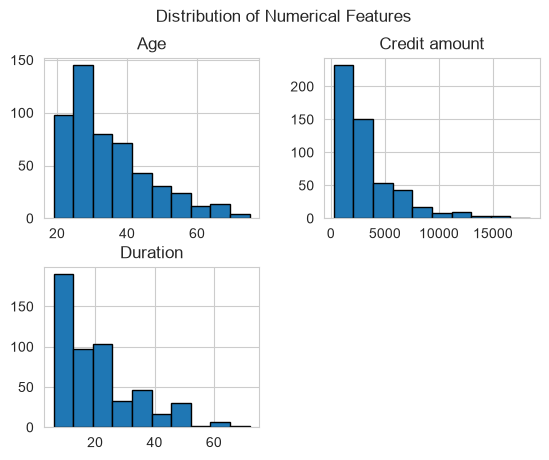

In [16]:
df[["Age","Credit amount","Duration"]].hist(bins=10,edgecolor="black")
plt.suptitle("Distribution of Numerical Features")
plt.show()

In [17]:
df.query("Duration>=60")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
18,63,male,2,own,little,little,6836,60,business,bad
176,24,female,3,own,moderate,moderate,7408,60,car,bad
199,60,female,3,free,moderate,moderate,14782,60,vacation/others,bad
358,24,male,2,own,moderate,moderate,5595,72,radio/TV,bad
378,27,male,3,own,little,moderate,14027,60,car,bad
489,42,male,2,free,little,moderate,6288,60,education,bad
507,36,male,2,rent,little,little,7297,60,business,bad


In [18]:
categorical_cols = ["Sex","Job","Housing","Saving accounts","Checking account", "Purpose"]

C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\1296126534.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data= df, x = col, palette = "Set2", order = df [col].value_counts().index)
C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\1296126534.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data= df, x = col, palette = "Set2", order = df [col].value_counts().index)
C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\1296126534.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data= df, x = col, palette = "Set2", order = df [col]

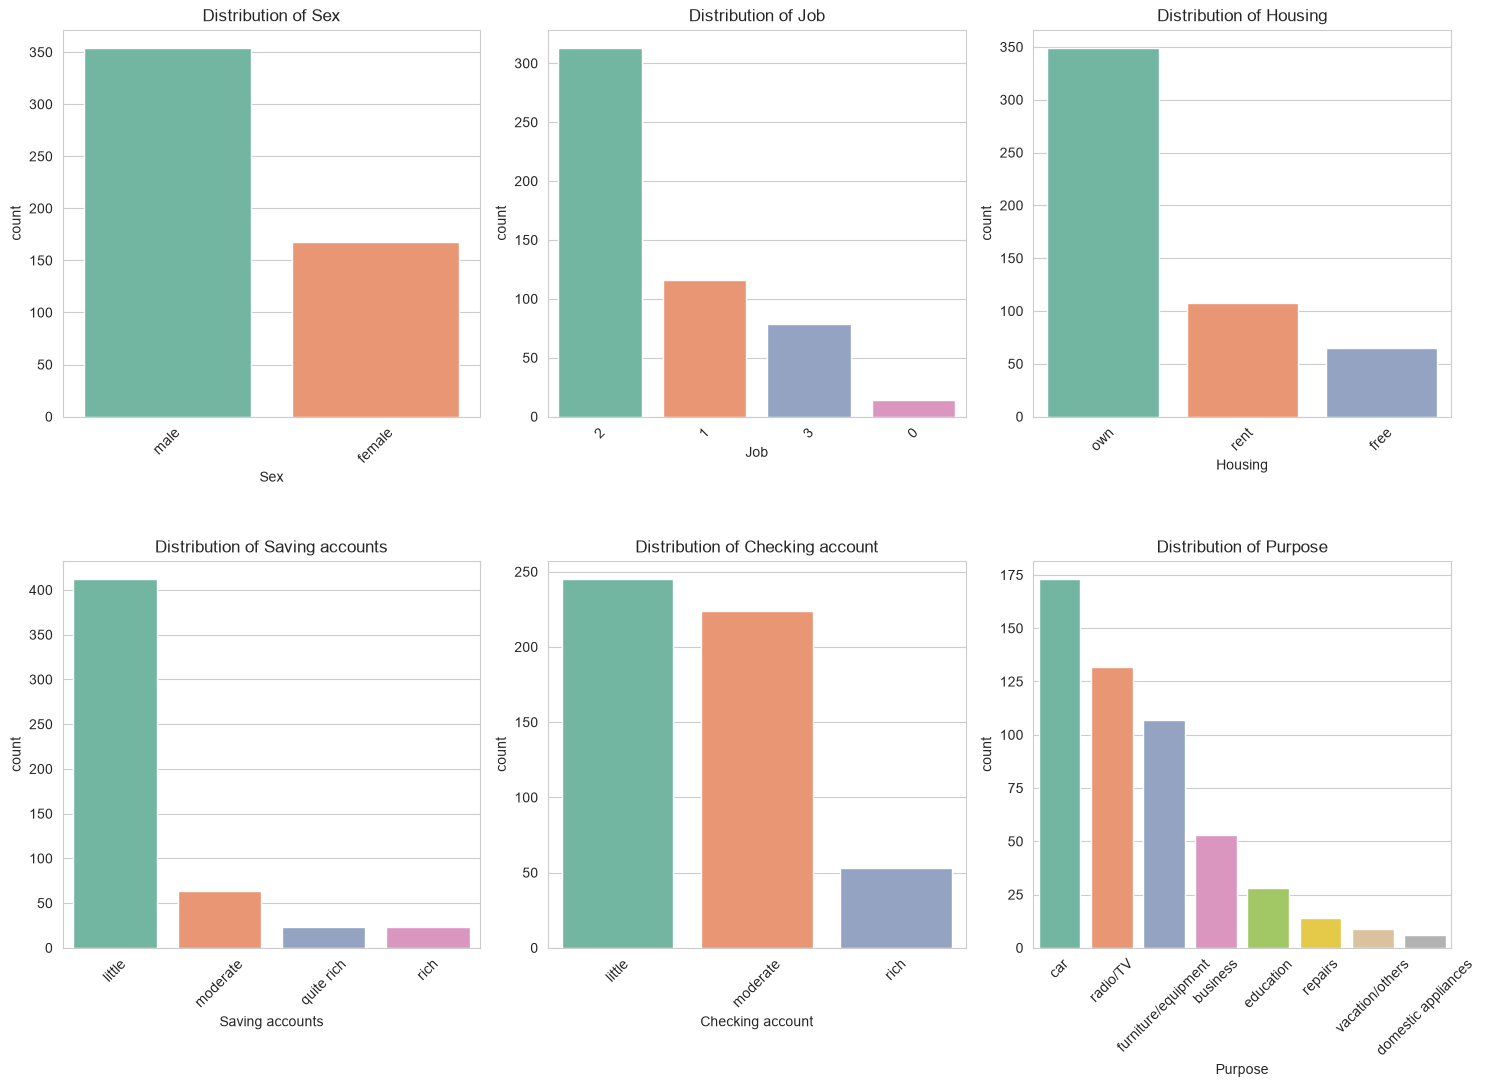

In [19]:
plt.figure(figsize=(15,15))
for i, col in enumerate(categorical_cols):
  plt.subplot(3,3,i+1)
  sns.countplot(data= df, x = col, palette = "Set2", order = df [col].value_counts().index)
  plt.title(f"Distribution of {col}")
  plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [20]:
cor=df[['Age','Job','Credit amount','Duration']].corr()

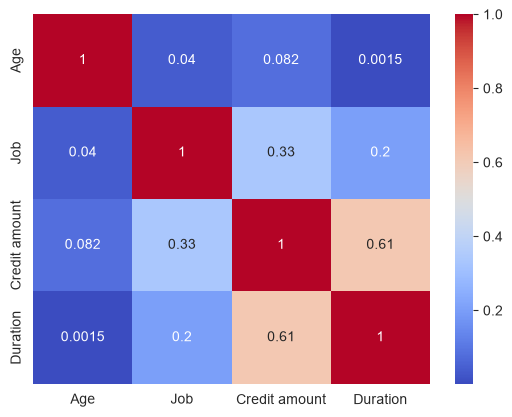

In [21]:
sns.heatmap(cor,annot=True,cmap='coolwarm')
plt.show()

In [22]:
df.groupby("Job")["Credit amount"].mean()

Job
0    1767.857143
1    2250.715517
2    3129.130990
3    5648.784810
Name: Credit amount, dtype: float64

In [23]:
df.groupby("Sex")["Credit amount"].mean()

Sex
female    2937.202381
male      3440.833333
Name: Credit amount, dtype: float64

In [24]:
pd.pivot_table(df, values="Credit amount",index="Housing",columns="Purpose")

Purpose,business,car,domestic appliances,education,furniture/equipment,radio/TV,repairs,vacation/others
Housing,,,,,,,,
free,4705.000000,5180.314286,NaN,5314.250000,4419.444444,2097.000000,1190.0,7842.666667
own,3725.973684,3120.485437,1333.5,2625.076923,3031.100000,2307.613861,2993.5,10321.833333
rent,6180.833333,3398.285714,NaN,2627.857143,2890.285714,2138.000000,2384.0,NaN


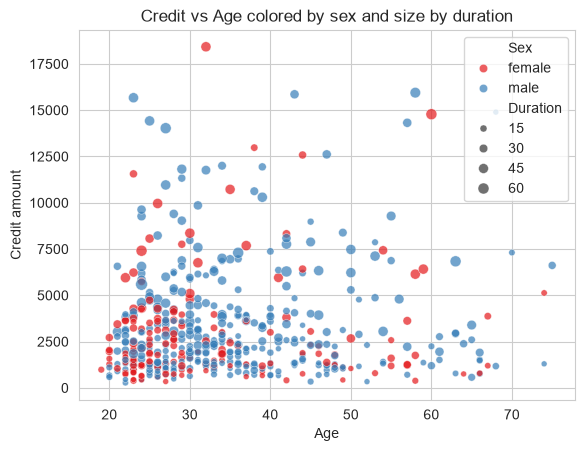

In [25]:
sns.scatterplot(data=df,x="Age",y="Credit amount",hue="Sex",size="Duration",alpha=0.7,palette="Set1")
plt.title("Credit vs Age colored by sex and size by duration")
plt.show()

C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\1361179444.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df,x="Saving accounts",y="Credit amount",palette ="Set1")


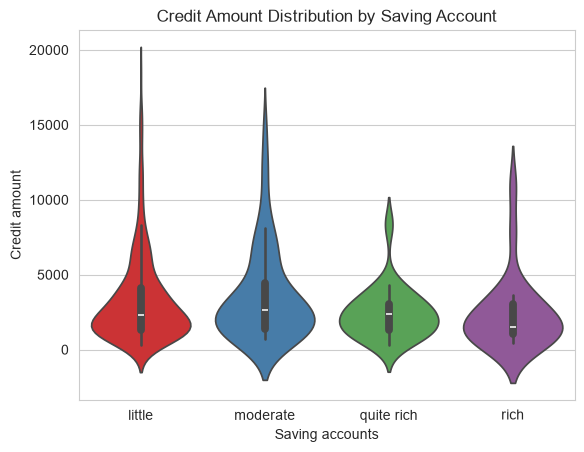

In [26]:
sns.violinplot(data=df,x="Saving accounts",y="Credit amount",palette ="Set1")
plt.title("Credit Amount Distribution by Saving Account")
plt.show()

In [27]:
df["Risk"].value_counts(normalize=True)*100

Risk
good    55.747126
bad     44.252874
Name: proportion, dtype: float64

C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\2523104685.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x = "Risk", y = col, palette="Pastel2")
C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\2523104685.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x = "Risk", y = col, palette="Pastel2")
C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\2523104685.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df, x = "Risk", y = col, palette="Pastel2")


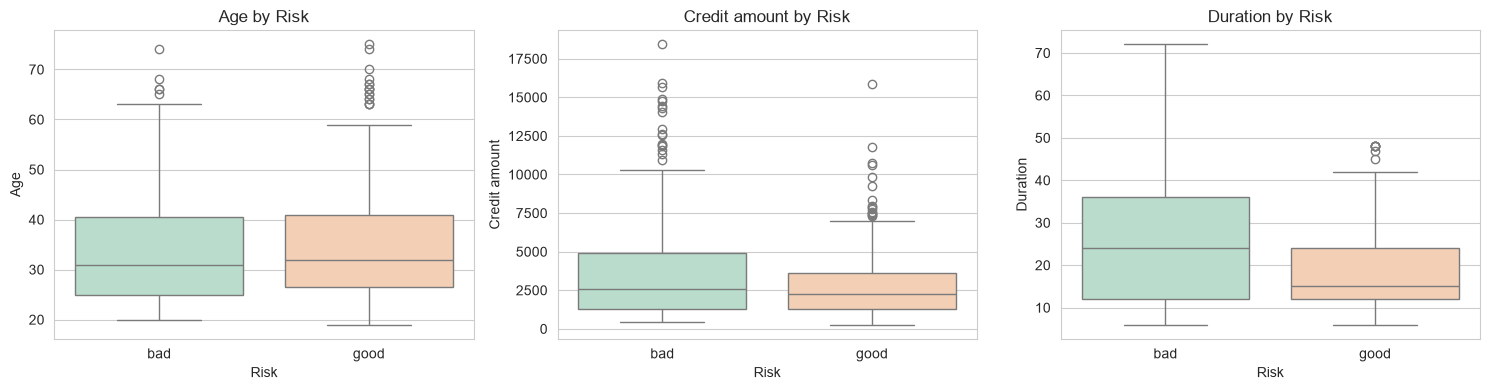

In [28]:
plt.figure(figsize=(15,4))
for i, col in enumerate(["Age", "Credit amount","Duration"]):
     plt.subplot(1,3, i+1) 
     sns.boxplot(data = df, x = "Risk", y = col, palette="Pastel2") 
     plt.title(f"{col} by Risk")


plt.tight_layout()

plt.show()

In [29]:
df.groupby("Risk")[["Age","Credit amount","Duration"]].mean()

,Age,Credit amount,Duration
Risk,,,
bad,34.147186,3881.090909,25.445887
good,35.477663,2800.594502,18.079038


In [30]:
categorical_cols

['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

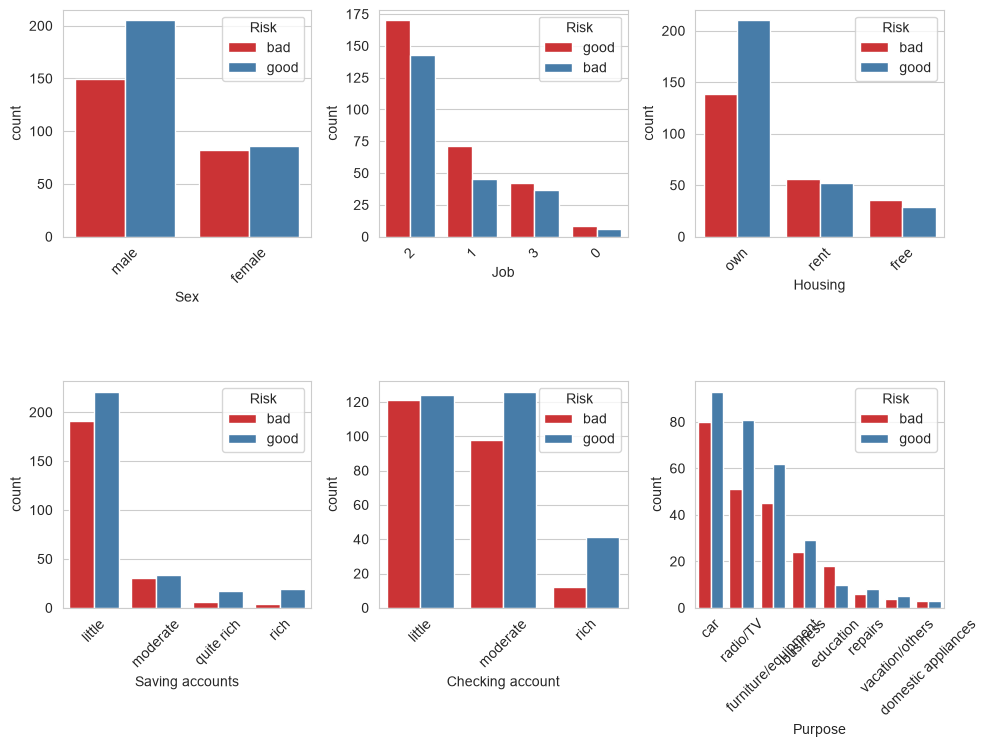

In [31]:
plt.figure(figsize=(10,10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1)
    sns.countplot(data = df, x = col, hue = "Risk", palette = "Set1", order = df [col].value_counts().index)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [32]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

In [33]:
features=["Age", "Sex", "Job", "Housing", "Saving accounts", "Checking account",
       "Credit amount", "Duration"]

In [34]:
target="Risk"

In [35]:
df_model = df[features+[target]].copy()

In [36]:
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,22,female,2,own,little,moderate,5951,48,bad
1,45,male,2,free,little,little,7882,42,good
2,53,male,2,free,little,little,4870,24,bad
3,35,male,3,rent,little,moderate,6948,36,good
4,28,male,3,own,little,moderate,5234,30,bad


In [37]:
from sklearn.preprocessing import LabelEncoder
import joblib

In [38]:
cat_cols = df_model.select_dtypes(include="object").columns.drop("Risk")

C:\Users\Vansh\AppData\Local\Temp\ipykernel_4680\714141096.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_model.select_dtypes(include="object").columns.drop("Risk")


In [39]:
le_dict={}

In [40]:
cat_cols

Index(['Sex', 'Housing', 'Saving accounts', 'Checking account'], dtype='str')

In [41]:
for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    le_dict[col] = le
    joblib.dump(le, f"{col}_encoder.pkl")

In [42]:
le_target = LabelEncoder()

In [43]:
target

'Risk'

In [44]:
df_model[target]=le_target.fit_transform(df_model[target])

In [45]:
df_model[target].value_counts()

Risk
1    291
0    231
Name: count, dtype: int64

In [46]:
joblib.dump(le_target,"target_encoder.pkl")

['target_encoder.pkl']

In [47]:
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,22,0,2,1,0,1,5951,48,0
1,45,1,2,0,0,0,7882,42,1
2,53,1,2,0,0,0,4870,24,0
3,35,1,3,2,0,1,6948,36,1
4,28,1,3,1,0,1,5234,30,0


In [48]:
from sklearn.model_selection import train_test_split

In [49]:
X=df_model.drop(target,axis=1)

In [50]:
Y=df_model[target]

In [51]:
X

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration
0,22,0,2,1,0,1,5951,48
1,45,1,2,0,0,0,7882,42
2,53,1,2,0,0,0,4870,24
3,35,1,3,2,0,1,6948,36
4,28,1,3,1,0,1,5234,30
...,...,...,...,...,...,...,...,...
517,48,1,1,1,0,1,1743,24
518,30,1,3,1,0,0,3959,36
519,40,1,3,1,0,0,3857,30
520,23,1,2,0,0,0,1845,45


In [52]:
target

'Risk'

In [53]:
Y

0      0
1      1
2      0
3      1
4      0
      ..
517    1
518    1
519    1
520    0
521    1
Name: Risk, Length: 522, dtype: int64

In [54]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,stratify=Y,random_state=42)

In [55]:
X_train.shape

(417, 8)

In [56]:
X_test.shape

(105, 8)

In [57]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score

In [58]:
def train_model(model,param_grid,X_train,Y_train,X_test,Y_test):
    grid = GridSearchCV(model ,param_grid,cv=5,scoring="accuracy",n_jobs=-1)
    grid.fit(X_train,Y_train)
    best_model= grid.best_estimator_
    Y_pred= best_model.predict(X_test)
    acc=accuracy_score(Y_test,Y_pred)
    return best_model,acc,grid.best_params_


In [59]:
dt=DecisionTreeClassifier(random_state=42,class_weight="balanced")
dt_param_grid ={
    "max_depth":[3,5,7,10,None],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]
}

In [60]:
best_dt,acc_dt,params_dt=train_model(dt,dt_param_grid,X_train,Y_train,X_test,Y_test)

In [61]:
print("Decision Tree Accuracy",acc_dt)

Decision Tree Accuracy 0.6


In [62]:
print("Best parameters",params_dt)

Best parameters {'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 10}


In [63]:
rf=RandomForestClassifier(random_state=42,class_weight="balanced", n_jobs=-1)

In [64]:
rf_param_grid={
    "n_estimators":[100,200],
    "max_depth":[5,7,10,None],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]

}

In [65]:
best_rf,acc_rf,params_rf=train_model(rf,rf_param_grid,X_train,Y_train,X_test,Y_test)

In [66]:
print("Random Forest Accuracy",acc_rf)

Random Forest Accuracy 0.6666666666666666


In [67]:
print("Best params",params_rf)

Best params {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 200}


In [68]:
et=ExtraTreesClassifier(random_state=42,class_weight="balanced",n_jobs=-1)

In [69]:
et_param_grid={
    "n_estimators":[100,200],
    "max_depth":[5,7,10,None],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]

}

In [70]:
best_et,acc_et,params_et=train_model(et,et_param_grid,X_train,Y_train,X_test,Y_test)

In [71]:
print("Extra Trees Accuracy",acc_et)

Extra Trees Accuracy 0.6285714285714286


In [72]:
 print("Best params",params_et)

Best params {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 100}


In [73]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    random_state=42
)

In [74]:
ada_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.01, 0.1, 0.2],
    "estimator__max_depth": [5, 7, 10, None],
    "estimator__min_samples_split": [2, 5, 10],
    "estimator__min_samples_leaf": [1, 2, 4],
}

In [75]:
best_ada, acc_ada, params_ada = train_model(ada, ada_param_grid, X_train, Y_train, X_test, Y_test)

In [76]:
print("AdaBoost Accuracy", acc_ada)

AdaBoost Accuracy 0.6952380952380952


In [77]:
print("Best params", params_ada)

Best params {'estimator__max_depth': 5, 'estimator__min_samples_leaf': 2, 'estimator__min_samples_split': 10, 'learning_rate': 0.2, 'n_estimators': 100}


In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 417
Testing samples: 105


In [79]:
models = {
    "Decission Tree": make_pipeline(
        StandardScaler(),
        DecisionTreeClassifier()
    ),

    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier()
    ),

    "Ada Boost": make_pipeline(
        StandardScaler(),
        AdaBoostClassifier()
    ),
    "Extra tree": make_pipeline(
         StandardScaler(),
        ExtraTreesClassifier()
    ),

}

In [80]:
cv_results = {}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        Y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results[name] = scores

    print(name)
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print("Standard deviation:", scores.std())
    print("-" * 50)

Decission Tree
Fold scores: [0.51190476 0.55952381 0.65060241 0.42168675 0.55421687]
Mean accuracy: 0.5395869191049913
Standard deviation: 0.07430034527460098
--------------------------------------------------
Random Forest
Fold scores: [0.61904762 0.77380952 0.6626506  0.63855422 0.61445783]
Mean accuracy: 0.6617039586919105
Standard deviation: 0.05857682865126285
--------------------------------------------------
Ada Boost
Fold scores: [0.51190476 0.66666667 0.61445783 0.71084337 0.62650602]
Mean accuracy: 0.6260757314974181
Standard deviation: 0.06633754321864499
--------------------------------------------------
Extra tree
Fold scores: [0.53571429 0.71428571 0.6626506  0.56626506 0.65060241]
Mean accuracy: 0.6259036144578314
Standard deviation: 0.06551738600583058
--------------------------------------------------


In [81]:
best_rf.predict(X_test)

array([0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1])

In [82]:
joblib.dump(best_rf,"Random_Forest_credit_model.pkl")

['Random_Forest_credit_model.pkl']